# Bons e Maus Pagadores — Modelagem

Modelagem · Give Me Some Credit <br>
Por [Leonardo Dias Trindade da Silva](https://github.com/LeoDiasTrindade)

**Pergunta:** a partir do histórico de crédito de um cliente, qual a probabilidade de ele ter um atraso grave (90 dias ou mais) nos próximos 2 anos?

Este notebook continua o `01_eda.ipynb`. As regras de limpeza decididas na EDA foram movidas para `src/bons_maus_pagadores/preprocessamento.py`, para que EDA e modelagem usem exatamente a mesma regra.

**Roteiro** (cada passo remete a uma aula):
1. Divisão treino/teste estratificada; o teste fica trancado até o fim (Aula 10)
2. Pré-processamento dentro da Pipeline, sem leakage (Aula 10)
3. Baseline: por que acurácia engana (Aula 6)
4. Regressão logística: transformação log, ridge × lasso, escolha de C por validação cruzada (Aulas 9 e 11)
5. Random Forest: tamanho mínimo da folha e viés-variância (Aula 6 e aula de 13/11)
6. Avaliação final no teste: ROC/AUC e log-loss (Aulas 6 e 10)
7. Limiar de decisão e matriz de confusão (Aula 9)
8. Interpretação: odds ratio e importância das features (Aula 9)
9. Submissão Kaggle (opcional)

---

In [1]:
%matplotlib inline
import time, warnings
from pathlib import Path

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, KBinsDiscretizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, log_loss, accuracy_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             precision_score, recall_score)

from bons_maus_pagadores.preprocessamento import (
    TARGET_NAME, carregar_treino, carregar_teste_kaggle, preparar_features, log_cauda_longa)

# Aviso interno do sklearn 1.9 (RandomForest com n_jobs dentro do GridSearchCV); não afeta resultados
warnings.filterwarnings('ignore', message='.*sklearn.utils.parallel.delayed.*')

SEED = 42
RAIZ = Path.cwd().parent
FIG_DIR = RAIZ / 'docs' / 'paper' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Estilo dos gráficos (rótulos em inglês: as figuras vão para o artigo)
AZUL, LARANJA, VERDE = '#2a78d6', '#eb6834', '#1baf7a'
CINZA, TEXTO, TEXTO_2 = '#8a8984', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 10.5, 'axes.labelsize': 10,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TEXTO_2, 'axes.titlecolor': TEXTO,
    'axes.titlelocation': 'left', 'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'lines.linewidth': 2, 'legend.frameon': False,
})

def salvar(fig, nome):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG_DIR / f'{nome}.{ext}')

NOMES_CURTOS = {
    'RevolvingUtilizationOfUnsecuredLines': 'Revolving utilization',
    'age': 'Age',
    'NumberOfTime30-59DaysPastDueNotWorse': 'Times 30-59 days late',
    'DebtRatio': 'Debt ratio',
    'MonthlyIncome': 'Monthly income',
    'NumberOfOpenCreditLinesAndLoans': 'Open credit lines',
    'NumberOfTimes90DaysLate': 'Times 90+ days late',
    'NumberRealEstateLoansOrLines': 'Real-estate loans',
    'NumberOfTime60-89DaysPastDueNotWorse': 'Times 60-89 days late',
    'NumberOfDependents': 'Dependents',
    'Missing-MonthlyIncome': 'Flag: income missing',
    'Missing-NumberOfDependents': 'Flag: dependents missing',
    'Atraso-codigo-invalido': 'Flag: late codes 96/98',
    'Rotativo-invalido': 'Flag: revolving > 400%',
}

## 1. Divisão treino/teste

Uso apenas o `cs-training.csv` (o `cs-test.csv` do Kaggle não tem rótulo). Separo 20% como **teste**, estratificado pelo alvo para manter a mesma taxa de inadimplência (6,7%) nos dois lados. O teste fica trancado: todas as escolhas (transformações, C, tamanho da folha, limiar) são feitas com validação cruzada estratificada de 5 folds dentro dos 80% de treino. O teste é aberto uma única vez, na seção 6 (Aula 10: *cross-validation chooses, the test grades*).

In [3]:
df = carregar_treino()
X, y = df.drop(columns=TARGET_NAME), df[TARGET_NAME]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

pd.DataFrame({'linhas': [len(y_treino), len(y_teste)],
              'inadimplentes': [y_treino.sum(), y_teste.sum()],
              'taxa': [y_treino.mean(), y_teste.mean()]},
             index=['treino', 'teste']).round(4)

,linhas,inadimplentes,taxa
treino,120000,8021,0.0668
teste,30000,2005,0.0668


### Resumo visual da EDA (só no treino)

Antes de modelar, uma figura que resume os achados do `01_eda` e que vai para o artigo. Uso apenas o treino para não olhar o teste.

- As contagens de atraso e o uso do rotativo têm relação forte e monotônica com a inadimplência.
- A idade tem relação decrescente.
- Os indicadores criados na EDA carregam informação: renda faltante tem taxa *menor* que a média, e os códigos 96/98 têm taxa de mais de 50%.

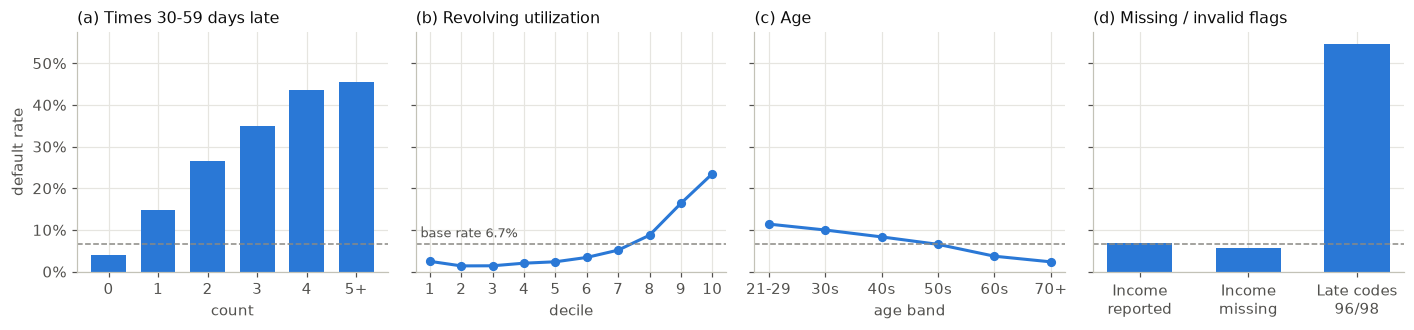

{'Income\nreported': np.float64(0.0696), 'Income\nmissing': np.float64(0.0557), 'Late codes\n96/98': np.float64(0.5467)}


In [4]:
eda = preparar_features(X_treino).assign(alvo=y_treino.values)
taxa_base = y_treino.mean()

fig, axes = plt.subplots(1, 4, figsize=(13, 3.1), sharey=True)

# (a) atrasos de 30-59 dias
atraso = eda['NumberOfTime30-59DaysPastDueNotWorse'].clip(upper=5)
t = eda.groupby(atraso)['alvo'].mean()
axes[0].bar(['0', '1', '2', '3', '4', '5+'], t.values, color=AZUL, width=0.7)
axes[0].set(title='(a) Times 30-59 days late', xlabel='count')

# (b) uso do rotativo por decil
decil = pd.qcut(eda['RevolvingUtilizationOfUnsecuredLines'], 10, labels=False) + 1
t = eda.groupby(decil)['alvo'].mean()
axes[1].plot(t.index, t.values, color=AZUL, marker='o', markersize=5)
axes[1].set(title='(b) Revolving utilization', xlabel='decile', xticks=range(1, 11))

# (c) idade em faixas
faixa = pd.cut(eda['age'], [20, 30, 40, 50, 60, 70, 110], right=False)
t = eda.groupby(faixa, observed=True)['alvo'].mean()
axes[2].plot(range(len(t)), t.values, color=AZUL, marker='o', markersize=5)
axes[2].set(title='(c) Age', xlabel='age band', xticks=range(len(t)),
            xticklabels=['21-29', '30s', '40s', '50s', '60s', '70+'])

# (d) indicadores
grupos = {'Income\nreported': eda['Missing-MonthlyIncome'] == 0,
          'Income\nmissing': eda['Missing-MonthlyIncome'] == 1,
          'Late codes\n96/98': eda['Atraso-codigo-invalido'] == 1}
taxas = [eda.loc[m, 'alvo'].mean() for m in grupos.values()]
axes[3].bar(list(grupos), taxas, color=AZUL, width=0.6)
axes[3].set(title='(d) Missing / invalid flags')

for ax in axes:
    ax.axhline(taxa_base, color=CINZA, linestyle='--', linewidth=1)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[0].set_ylabel('default rate')
axes[1].text(0.7, taxa_base + 0.008, f'base rate {taxa_base:.1%}', color=TEXTO_2, va='bottom', ha='left', fontsize=8.5)
fig.tight_layout()
salvar(fig, 'fig_eda')
plt.show()

print({k: round(v, 4) for k, v in zip(grupos, taxas)})

## 2. Pré-processamento sem leakage

No `01_eda` a imputação pela mediana foi ajustada na base inteira, o que é aceitável para explorar, mas seria leakage na avaliação (Aula 10, *door 1: preprocessing before splitting*). Aqui separo os passos em dois tipos:

| Passo | Aprende com os dados? | Onde roda |
|---|---|---|
| `preparar_features`: indicadores de faltante/inválido + anular valores impossíveis (idade 0, rotativo > 400%, códigos 96/98, DebtRatio quando a renda falta) | Não (regra linha a linha) | Pode rodar em qualquer lugar |
| `log_cauda_longa`: log(1 + x) nas features assimétricas | Não | idem |
| `SimpleImputer(median)`, `StandardScaler` | **Sim** (mediana, média, desvio) | Dentro da Pipeline, ajustado só nos folds de treino |
| Modelo | **Sim** | idem |

A padronização é necessária para a regressão logística regularizada: a penalidade compara o tamanho dos coeficientes, então as unidades não podem decidir (Aula 11, *standardise the features first*). Os indicadores 0/1 passam sem padronizar, para que o coeficiente deles seja lido diretamente como "flag ligada vs desligada".

A Random Forest não precisa de padronização: cada divisão da árvore olha uma feature por vez, e a ordem dos valores não muda com a escala.

In [5]:
FEATURES_NUM = list(X.columns)  # as 10 features originais
INDICADORES = ['Missing-MonthlyIncome', 'Missing-NumberOfDependents',
               'Atraso-codigo-invalido', 'Rotativo-invalido']

def pipeline_logistica(log=True, C=1.0, l1_ratio=0.0):
    passos_num = [FunctionTransformer(log_cauda_longa, feature_names_out='one-to-one')] if log else []
    passos_num += [SimpleImputer(strategy='median'), StandardScaler()]
    pre = ColumnTransformer([('num', make_pipeline(*passos_num), FEATURES_NUM),
                             ('ind', 'passthrough', INDICADORES)],
                            verbose_feature_names_out=False)
    return Pipeline([('limpeza', FunctionTransformer(preparar_features)),
                     ('pre', pre),
                     ('modelo', LogisticRegression(C=C, l1_ratio=l1_ratio,
                                                   solver='liblinear', max_iter=2000))])

def pipeline_floresta(min_samples_leaf=50, n_estimators=300):
    return Pipeline([('limpeza', FunctionTransformer(preparar_features)),
                     ('imputacao', SimpleImputer(strategy='median')),
                     ('modelo', RandomForestClassifier(
                         n_estimators=n_estimators, min_samples_leaf=min_samples_leaf,
                         max_features='sqrt', n_jobs=-1, random_state=SEED))])

METRICAS = {'auc': 'roc_auc', 'log_loss': 'neg_log_loss'}
resultados_cv = {}

def avaliar_cv(nome, modelo, n_jobs=5):
    inicio = time.time()
    s = cross_validate(modelo, X_treino, y_treino, cv=cv, scoring=METRICAS, n_jobs=n_jobs)
    resultados_cv[nome] = {'AUC (CV)': s['test_auc'].mean(), 'AUC desvio': s['test_auc'].std(),
                           'log-loss (CV)': -s['test_log_loss'].mean(),
                           'tempo (s)': time.time() - inicio}
    return pd.Series(resultados_cv[nome]).round(4)

## 3. Baseline: por que acurácia engana

93,3% dos clientes pagam. Um "modelo" que diz que **todo mundo paga** já acerta 93,3%, sem olhar dado nenhum (Aula 6, *back to the loan portfolio*). Por isso não uso acurácia para escolher modelos:

- **AUC** (área sob a curva ROC, Aula 10): a chance de um inadimplente sorteado receber um score maior que um bom pagador sorteado. Não depende de limiar e é a métrica da competição do Kaggle.
- **log-loss** (Aula 6): pontua a probabilidade que o modelo deu ao que de fato aconteceu. É a função de custo da regressão logística e é o critério que uso para escolher hiperparâmetros (*keep the candidate with the lowest mean error*, Aula 10).

O baseline abaixo prevê a taxa base (6,7%) para todos: AUC 0,5 e o log-loss de referência.

In [6]:
print(f'Acurácia de "todo mundo paga" no treino: {1 - y_treino.mean():.3f}')
avaliar_cv('Baseline (taxa base)', DummyClassifier(strategy='prior'))

Acurácia de "todo mundo paga" no treino: 0.933


AUC (CV)         0.5000
AUC desvio       0.0000
log-loss (CV)    0.2454
tempo (s)        2.5825
dtype: float64

## 4. Regressão logística

Método principal. Motivos (Aula 9):
- dá uma **probabilidade** p = σ(β₀ + β·x), que o banco transforma em decisão escolhendo um limiar;
- cada β tem leitura direta: e^β é o **odds ratio**, o que explica uma recusa de crédito a um cliente ou a um regulador;
- é o *baseline* que qualquer modelo mais complexo precisa superar.

### 4.1 Transformação log nas features de cauda longa

A EDA mostrou assimetria muito alta (skew de 127 na renda, 81 no DebtRatio). O modelo é linear em β, não em x (Aula 7), então posso trocar x por log(1 + x) sem sair da regressão logística.

In [7]:
display(avaliar_cv('LogReg sem log', pipeline_logistica(log=False)))
avaliar_cv('LogReg com log', pipeline_logistica(log=True))

AUC (CV)         0.8507
AUC desvio       0.0043
log-loss (CV)    0.1878
tempo (s)        0.9222
dtype: float64

AUC (CV)         0.8522
AUC desvio       0.0045
log-loss (CV)    0.1846
tempo (s)        0.8243
dtype: float64

### 4.2 Regularização: ridge × lasso e escolha de C

No scikit-learn, `C = 1/α`: C pequeno = penalidade forte (Aula 11). Comparo ridge (`l1_ratio=0`, ‖β‖²) e lasso (`l1_ratio=1`, ‖β‖₁) numa grade de C, com validação cruzada de 5 folds. O C escolhido é o de menor log-loss médio.

In [8]:
grade_lr = GridSearchCV(
    pipeline_logistica(log=True),
    {'modelo__C': np.logspace(-4, 2, 7), 'modelo__l1_ratio': [0.0, 1.0]},
    cv=cv, scoring=METRICAS, refit='log_loss', n_jobs=-1)
inicio = time.time()
grade_lr.fit(X_treino, y_treino)
print(f'{time.time() - inicio:.1f}s | melhor: {grade_lr.best_params_}')

res_lr = (pd.DataFrame(grade_lr.cv_results_)
          .assign(C=lambda d: d.param_modelo__C.astype(float),
                  penalidade=lambda d: d.param_modelo__l1_ratio.map({0.0: 'ridge', 1.0: 'lasso'}),
                  auc=lambda d: d.mean_test_auc, auc_dp=lambda d: d.std_test_auc,
                  log_loss=lambda d: -d.mean_test_log_loss)
          [['penalidade', 'C', 'auc', 'auc_dp', 'log_loss']])
res_lr.pivot(index='C', columns='penalidade', values=['auc', 'log_loss']).round(4)

14.6s | melhor: {'modelo__C': np.float64(10.0), 'modelo__l1_ratio': 0.0}


auc         log_loss        
penalidade   lasso   ridge    lasso   ridge
C                                          
0.0001      0.5000  0.8470   0.2931  0.2864
0.0010      0.8484  0.8517   0.1907  0.1947
0.0100      0.8502  0.8518   0.1858  0.1855
0.1000      0.8521  0.8521   0.1846  0.1847
1.0000      0.8522  0.8522   0.1846  0.1846
10.0000     0.8522  0.8522   0.1846  0.1846
100.0000    0.8522  0.8522   0.1846  0.1846

Quantos coeficientes o lasso mantém em cada C? (Aula 11: *count the non-zero lasso coefficients*)

In [9]:
nao_zeros = {}
for C in np.logspace(-4, 2, 7):
    m = pipeline_logistica(C=C, l1_ratio=1.0).fit(X_treino, y_treino)
    nao_zeros[C] = int((m['modelo'].coef_ != 0).sum())
pd.Series(nao_zeros, name='coeficientes não nulos (de 14)').to_frame().T

,0.0001,0.0010,0.0100,0.1000,1.0000,10.0000,100.0000
coeficientes não nulos (de 14),1,5,7,13,14,14,14


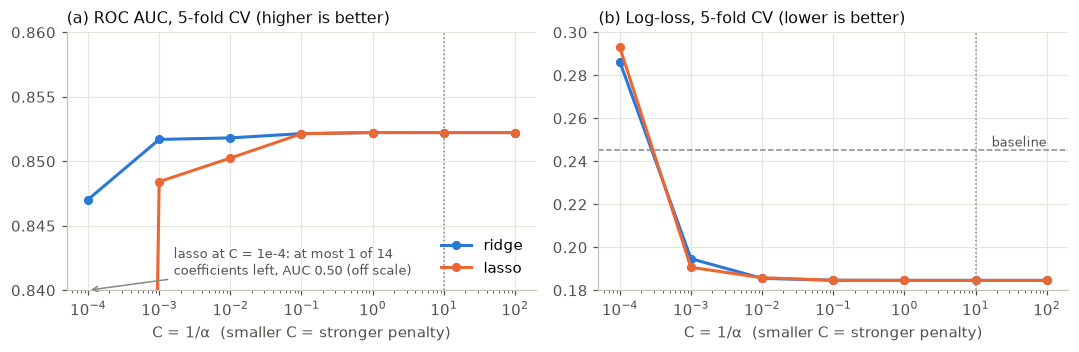

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for pen, cor in [('ridge', AZUL), ('lasso', LARANJA)]:
    d = res_lr[res_lr.penalidade == pen].sort_values('C')
    axes[0].plot(d.C, d.auc, color=cor, marker='o', markersize=5, label=pen)
    axes[1].plot(d.C, d.log_loss, color=cor, marker='o', markersize=5, label=pen)
axes[0].set(title='(a) ROC AUC, 5-fold CV (higher is better)', xscale='log',
            xlabel='C = 1/α  (smaller C = stronger penalty)', ylim=(0.84, 0.86))
axes[1].set(title='(b) Log-loss, 5-fold CV (lower is better)', xscale='log',
            xlabel='C = 1/α  (smaller C = stronger penalty)', ylim=(0.18, 0.30))
base_ll = resultados_cv['Baseline (taxa base)']['log-loss (CV)']
axes[1].axhline(base_ll, color=CINZA, linestyle='--', linewidth=1)
axes[1].text(100, base_ll, 'baseline', color=TEXTO_2, va='bottom', ha='right', fontsize=8.5)
c_best = grade_lr.best_params_['modelo__C']
for ax in axes:
    ax.axvline(c_best, color=CINZA, linewidth=1, linestyle=':')
axes[0].legend(loc='lower right')
axes[0].annotate('lasso at C = 1e-4: at most 1 of 14\ncoefficients left, AUC 0.50 (off scale)', xy=(1e-4, 0.84), xytext=(1.6e-3, 0.8412),
                 fontsize=8.5, color=TEXTO_2, arrowprops=dict(arrowstyle='->', color=CINZA))
fig.tight_layout()
salvar(fig, 'fig_regularizacao')
plt.show()

**Leitura:**
- Com C ≥ 0,1 ridge e lasso empatam: AUC ≈ 0,852 e log-loss ≈ 0,185, e o C escolhido (10) é praticamente sem penalidade. Com 120 mil linhas e 14 colunas (n ≫ p), a variância dos coeficientes já é pequena e a penalidade quase não tem o que corrigir (Aula 11: ridge ajuda quando há poucas linhas, muitas colunas ou colunas quase colineares).
- Com penalidade muito forte (C = 10⁻⁴), o lasso corta quase tudo (no máximo 1 de 14 coeficientes sobra) e o modelo vira o baseline (AUC 0,5). O ridge encolhe sem zerar: o AUC (que só olha a ordem dos scores) continua em 0,847, mas o log-loss sobe para 0,286, **pior que o baseline** (0,245), porque as probabilidades ficam todas espremidas perto do mesmo valor.
- Isso mostra por que escolho C pelo log-loss e não pelo AUC: o AUC não vê que as probabilidades ficaram ruins.

In [11]:
avaliar_cv('LogReg com log (C escolhido)', grade_lr.best_estimator_)

AUC (CV)         0.8522
AUC desvio       0.0045
log-loss (CV)    0.1846
tempo (s)        4.0669
dtype: float64

### 4.3 Experimento: bins nas features contínuas

A EDA mostrou relações não lineares (o rotativo, por exemplo). Como o modelo é linear em β, posso dar a ele uma coluna 0/1 por faixa de valor (20 quantis), na linha da ideia de WOE/binning que comecei no `01_eda` para a idade. As contagens de atraso ficam em log: elas são ~85% zeros e os quantis colapsariam num bin só.

In [12]:
CONTINUAS = ['RevolvingUtilizationOfUnsecuredLines', 'age', 'DebtRatio',
             'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans']
CONTAGENS = [c for c in FEATURES_NUM if c not in CONTINUAS]

lr_bins = Pipeline([
    ('limpeza', FunctionTransformer(preparar_features)),
    ('imputacao', SimpleImputer(strategy='median').set_output(transform='pandas')),
    ('pre', ColumnTransformer([
        ('bins', KBinsDiscretizer(n_bins=20, encode='onehot', strategy='quantile',
                                  quantile_method='averaged_inverted_cdf'), CONTINUAS),
        ('cont', make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), CONTAGENS),
        ('ind', 'passthrough', INDICADORES)])),
    ('modelo', LogisticRegression(max_iter=3000))])

with warnings.catch_warnings():
    warnings.simplefilter('ignore')  # avisos de bins repetidos em colunas com muitos empates
    display(avaliar_cv('LogReg com bins (experimento)', lr_bins, n_jobs=1))

AUC (CV)         0.8551
AUC desvio       0.0046
log-loss (CV)    0.1833
tempo (s)        2.5389
dtype: float64

Ganho de ~0,003 de AUC, dentro de um desvio padrão entre folds. Não compensa a perda de simplicidade (um coeficiente por faixa em vez de um por variável), então mantenho a regressão logística com log como modelo linear final. A diferença para a Random Forest (seção 5) não vem só de curvas em cada variável isolada; vem de **interações** entre variáveis, que a logística só captaria se eu criasse as colunas à mão (Aula 9, *logistic regression vs XGBoost*).